#$\quad$ Modelo de Tobin

## 1. Incorporación del *activo libre de riesgo*

- Denotaremos el activo libre de riesgo como **$R_f$**, el cual se caracteriza por:

  - **Rentabilidad garantizada**: Ofrece una rentabilidad fija conocida de antemano: $\quad Rendimiento \   R_{f,t} = r_f = cte \ \Rightarrow \ E(R_f) = r_f$

  - **Varianza cero**: Dado que $r_f = cte$, su varianza es cero: $\quad Var(r_f) =  \sigma^2_f = 0$

  - **Covarianza cero**: La covarianza del activo libre de riesgo con cualquier otro activo es cero: $\quad covar(r_f, r_i) = 0 \qquad \forall i$

- **Ejemplos comunes**: Bonos gubernamentales de países estables, como los bonos del Tesoro de EE. UU.

**¿Qué ocurre cuando creamos una cartera con un activo libre de riesgo y un activo con riesgo?**


- Activo libre de riesgo:
  - $E(r_f) = r_f$
  - $Var(r_f) = 0$

- Activo con riesgo:
  - $E(\tilde{r})=\mu$
  - $Var(\tilde{r})=\sigma^2$


Si creamos una cartera mixta $p$ con ponderaciones $w$ y $1 - w$:

- El retorno será:
  
  $$\boxed{r_p = (1-w) r_f +  w \mu} \tag{1}$$

  - La varianza será:
  
  $$\sigma^2_p = (1-w)^2 \times \sigma^2(r_f) + w^2\times \sigma^2(r) + 2(1-w)w \sigma(rf,r)$$
  $$\sigma^2_p = w^2 \sigma^2 \ \ \Rightarrow \ \boxed{\sigma_p = w\sigma} \tag{2}$$

El riesgo de la cartera depende únicamente de la inversión realizada en el activo con riesgo.

Despejando $w$ y sustituyendo en el retorno esperado, tenemos que:

- El retorno de la cartera mixta será:

**Si tenemos un retorno objetivo ($r_p$)**, despejamos $w$ de la ecuación $(1)$.

$$\quad \boxed{w = \frac{r_p - r_f}{\mu - r_f}}$$

**Si tenemos una volatilidad objetivo ($\sigma_p$)**, despejamos $w$ de la ecuación $(2)$.

$$\quad \boxed{w = \frac{\sigma_p}{\sigma}}$$



## 2. Ejemplo con activos reales


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import cvxpy as cp
import yfinance as yf
import seaborn as sns
#import gurobipy as gp
#from gurobipy import GRB
from scipy.interpolate import interp1d

plt.style.use('ggplot')

In [ ]:
# Date range
start = '2015-01-01'
end = '2019-12-30'

# Assets todos con retornos positivos
assets = ['BA']

# Downloading data
prices = yf.download(assets, start = start, end = end,auto_adjust=True)['Close'].dropna()
prices.columns = assets


[*********************100%***********************]  1 of 1 completed


We select the asset with ticker 'BA' and define the risk-free asset return $r_f$.

In [ ]:
rf = 0.03 # Risk-free asset return (annual)
rf_d = rf / 252 # Daily risk-free asset return

retornos_BA = np.log(prices).diff().dropna()
retornos_BA

,BA
Date,
2015-01-05,-0.006950
2015-01-06,-0.011848
2015-01-07,0.015407
2015-01-08,0.017527
2015-01-09,-0.001975
...,...
2019-12-20,-0.016629
2019-12-23,0.028700
2019-12-24,-0.013571


In [ ]:
mu_BA=retornos_BA.mean().iloc[0]*252
sigma_BA=retornos_BA.std().iloc[0]*np.sqrt(252)

print(f'La rentabilidad de BA es: {100*mu_BA.round(4)}%')
print(f'La volatilidad de BA es :{100*sigma_BA.round(4)}%')

La rentabilidad de BA es: 21.29%
La volatilidad de BA es :25.27%


In [ ]:
num_carteras = 1000

# Creamos arrays vacíos para guardar los resultados
rentabilidades = np.zeros(num_carteras)
volatilidades = np.zeros(num_carteras)

pesos_w1 = np.linspace(-1, 1, num_carteras) # inversión en BA

for idx, w1 in enumerate(pesos_w1):
  pesos_w2 = 1 - w1
  rentabilidades[idx] = ((rf * pesos_w2) + (mu_BA * w1))
  volatilidades[idx] = (sigma_BA * w1)

Text(0, 0.5, 'Retorno Esperado')

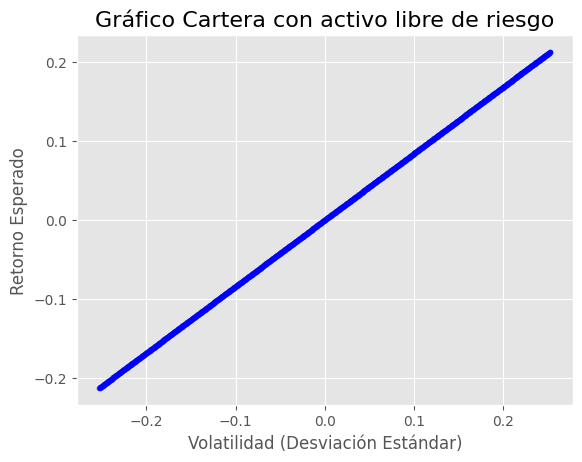

In [ ]:
plt.scatter(volatilidades, rentabilidades, color='blue', s=50, marker='.', alpha=0.7)
# Añadiendo títulos y etiquetas
plt.title('Gráfico Cartera con activo libre de riesgo', fontsize=16)
plt.xlabel('Volatilidad (Desviación Estándar)', fontsize=12)
plt.ylabel('Retorno Esperado', fontsize=12)


```markdown
**EJERCICIO**

Calcula la cartera formada por los dos activos anteriores y que tenga:

 a) un retorno anual del 14%

 b) un retorno anual del 25%

 c) una volatilidad anual del 7%
```

**A:**

In [ ]:
re = 0.14        # Rentabilidad objetivo

w = (re - rf) / (mu_BA-rf)
print(f'Invertimos el {100*w.round(4)}% en BA y el {100*(1-w).round(4)}% en el activo libre de riesgo')

Invertimos el 60.129999999999995% en BA y el 39.87%


In [ ]:
w*mu_BA + (1-w)*rf

np.float64(0.14)

**B:**

In [ ]:
re = 0.25        # Rentabilidad objetivo

w = (re - rf) / (mu_BA-rf)
print(f'Invertimos el {100*w.round(4)}% en BA y el {100*(1-w).round(4)}% en el activo libre de riesgo')

Invertimos el 120.27000000000001% en BA y el -20.27%


**C:**

In [ ]:
sigma = 0.07

w = sigma/ sigma_BA
print(f'Invertimos el {100*w.round(4)}% en BA y el {100*(1-w).round(4)}% en el activo libre de riesgo')

Invertimos el 27.700000000000003% en BA y el 72.3% en el activo libre de riesgo


In [ ]:
sigma_BA*w

np.float64(0.07)

## 3.Activos libre de riesgo y su combinación con otros activos

In [ ]:
# Date range
start = "2015-01-01"
end = "2019-12-30"

# Assets todos con retornos positivos
assets = [
    "BA",
    "BAX",
    "BMY",
    "CMCSA",
    "CNP",
    "CPB",
    "DE",
    "F",
    "GE",
    "HPQ",
    "JCI",
    "JPM",
    "KHC",
    "LUV",
    "MMC",
    "MO",
    "NI",
    "PCAR",
    "PSA",
    "SEE",
    "T",
    "TGT",
    "TMO",
    "TXT",
    "VZ",
    "ZION",
]

# Downloading data
prices = yf.download(assets, start=start, end=end, auto_adjust=True)["Close"]
prices.columns = assets

[*********************100%***********************]  26 of 26 completed
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['SEE', 'MMC']: YFTzMissingError('possibly delisted; no timezone found')


<Axes: >

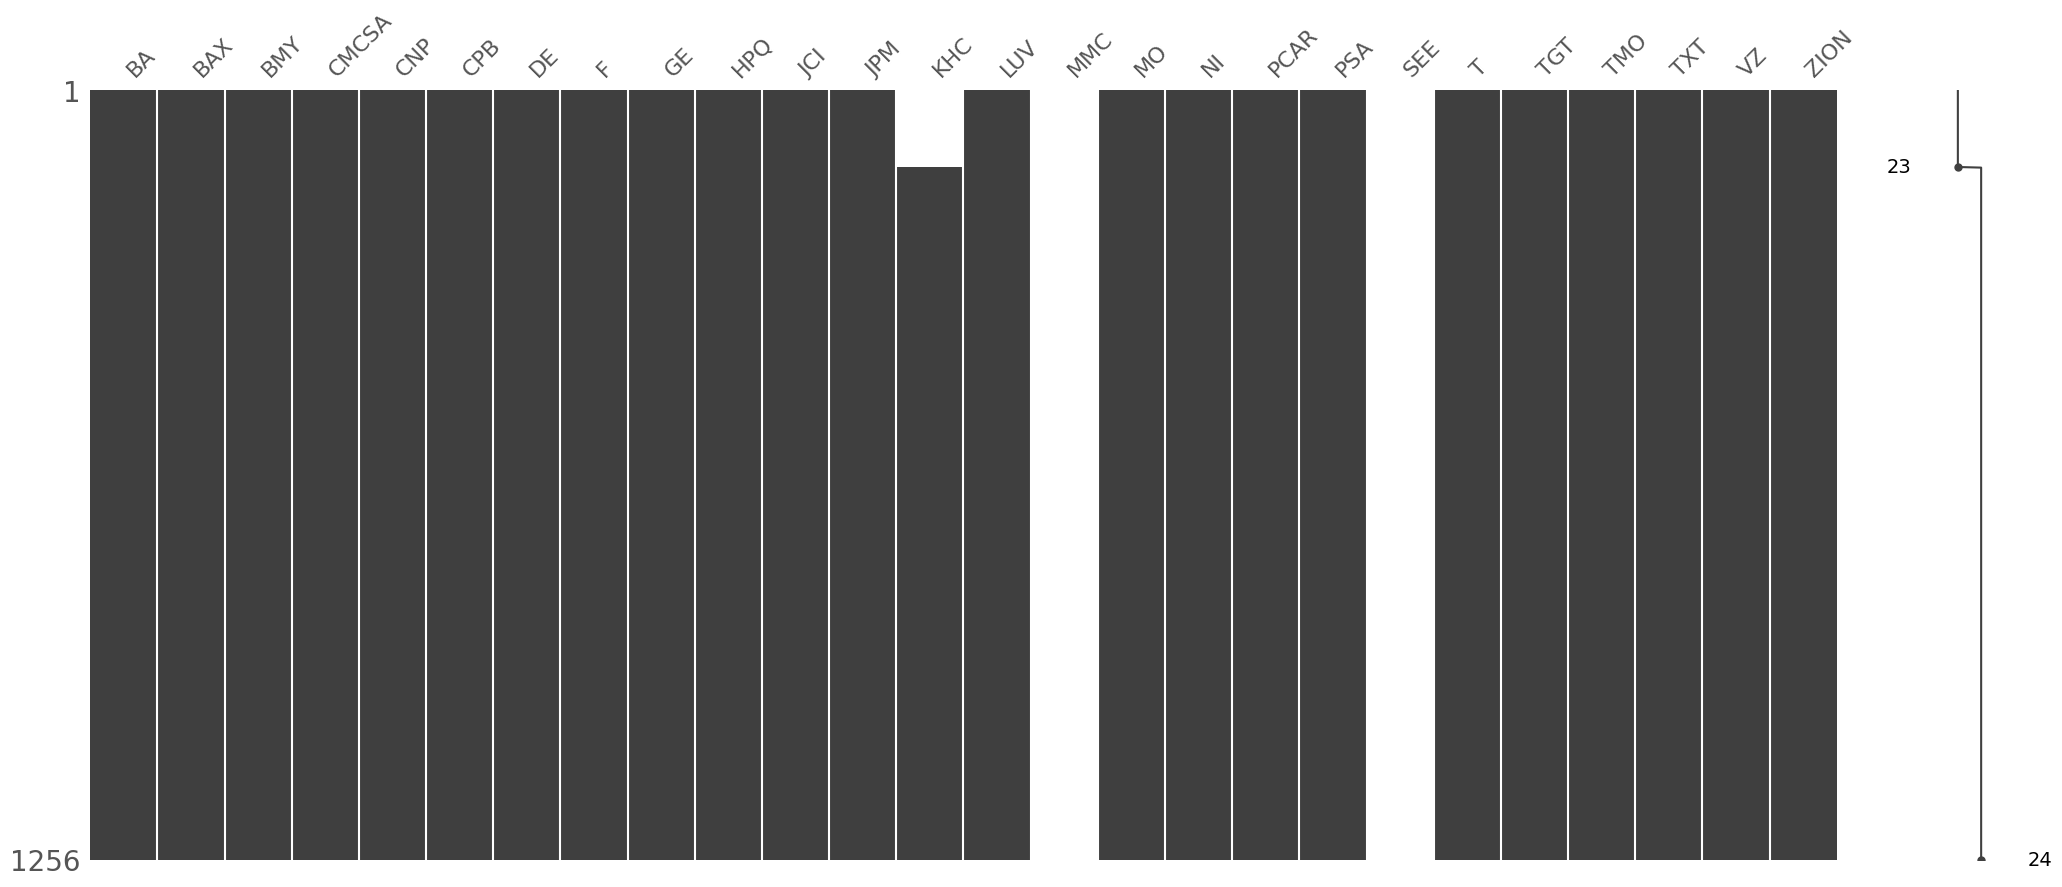

In [ ]:
import missingno as mso

mso.matrix(prices)

In [ ]:
# Volvemos a descargar los datos originales para restaurar el DataFrame prices
prices_raw = yf.download(assets, start=start, end=end, auto_adjust=True)["Close"]
prices_raw.columns = assets

# 1. Eliminamos primero las columnas de los activos que fallaron por completo (SEE y MMC)
prices_clean = prices_raw.dropna(axis=1, how='all')

# 2. Eliminamos las filas restantes con nulos parciales
prices_clean = prices_clean.dropna(axis=0, how='any')

# Actualizamos la variable prices global para que el resto del notebook funcione
prices = prices_clean

[*********************100%***********************]  26 of 26 completed
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['SEE', 'MMC']: YFTzMissingError('possibly delisted; no timezone found')


<Axes: >

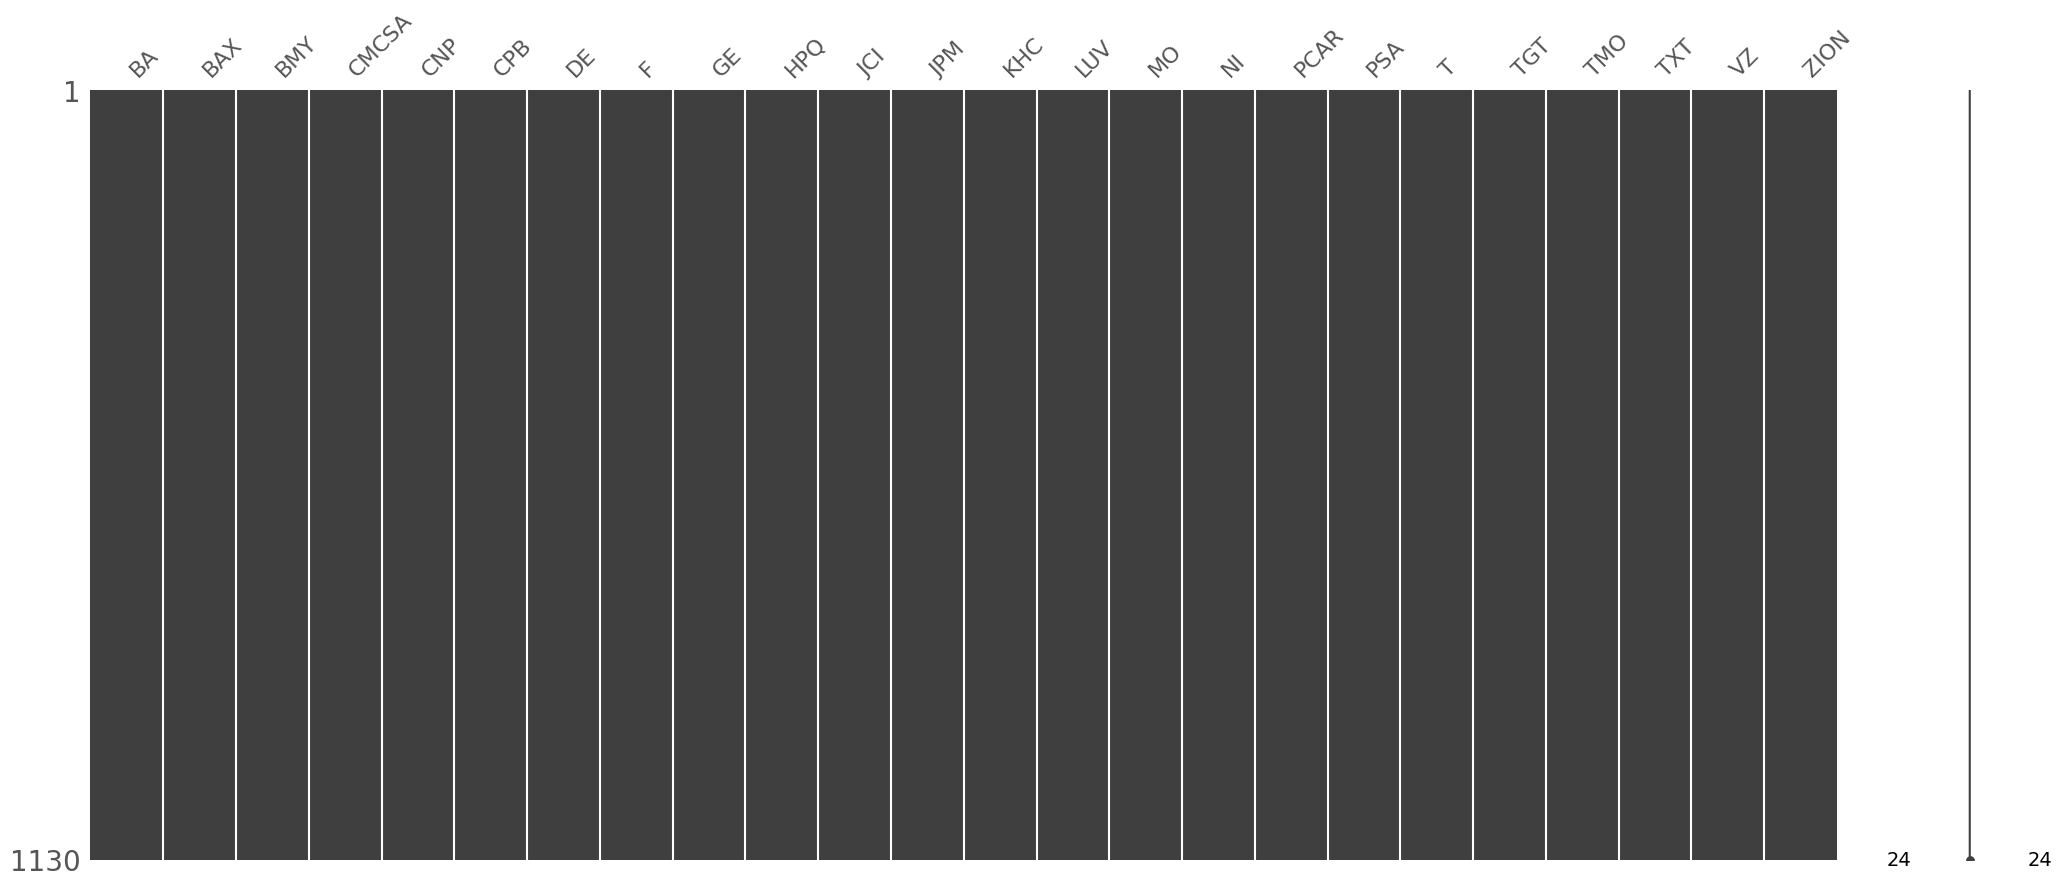

In [ ]:
mso.matrix(prices)

In [ ]:
retornos = np.log(prices).diff().dropna()

num_act = len(assets)

## 4.Línea del mercado de capitales (CML)

Determinemos formalmente la **línea del mercado de capitales (CML)**:

Para ello, analizamos la estructura de la frontera eficiente cuando introducimos el activo libre de riesgo:

$$\begin{gather}
max \text{   } w_0r_f+\mu^T w-\lambda w^T\Sigma w \tag{1}\\
s.t. \text{   } w_0+w=1 \nonumber
\end{gather}$$

donde:

- $w_0$ es la inversión en el activo libre de riesgo,

- $w$ es la inversión en el activo con riesgo,

- $r_f$ es el retorno del activo libre de riesgo,

- $\mu$ es el retorno esperado del activo con riesgo,

- $\lambda$ es el coeficiente de aversión al riesgo del inversor, y

- $\Sigma$ es la matriz de covarianzas.


La ecuación anterior se puede reescribir como un problema sin restricciones eliminando $w_0$, de la siguiente manera:

- eliminamos $w_0$ de la restricción
- lo sustituimos en la función objetivo
- simplificamos y reescribimos

$$\max \text{   } w^T\pi - \lambda w^T\Sigma \tag{2}w$$

donde $\pi=\mu-R_f$ es el vector de prima de riesgo.

Aplicamos la condición de primer orden (derivamos e igualamos a 0):

$$\pi-2\lambda\Sigma w=0 \tag{3}$$

Resolviendo, obtenemos los pesos de una cartera mixta eficiente:

$$w^*=\frac{1}{\lambda}\Sigma^{-1}\pi$$
$$w_0^*=1-w^{*T} \quad \Rightarrow w_0^*=1-\frac{1}{\lambda}i^T\Sigma^{-1}\pi$$

Observamos que cuando $\lambda \rightarrow +\infty$, la totalidad de la inversión se asigna al activo libre de riesgo.

El coeficiente $\lambda$ determina el peso del activo libre de riesgo en la cartera.

In [ ]:
#Calculamos la matriz de covarianzas y los retornos esperados
matriz_cov = retornos.cov().to_numpy() # Covariance matrix
retornos_esperados = retornos.mean().to_numpy() # Column vector expected return

In [ ]:
rf = 0.03 # Risk-free asset return (annual)
rf_d = rf / 252 # Daily risk-free asset return

z = np.linalg.inv(matriz_cov) @ (retornos_esperados - rf_d)

w_M = z / z.sum()
w_M

array([ 0.42588063,  0.43860024, -0.35368088,  0.01541245,  0.26585565,
        0.02609717,  0.25318465, -0.46814842, -0.58336078, -0.04364908,
       -0.01150981,  1.30088396, -0.63067619,  0.078616  , -0.12085183,
        0.42443641, -0.08211006, -0.06632457,  0.2919755 ,  0.17022555,
        0.54957756, -0.65059983,  0.04501083, -0.27484516])

## Otra alternativa para identificar la cartera M




Podríamos utilizar el optimizador CVXPY para estimar la cartera M, simplemente tendríamos que maximizar el **Sharpe ratio**:

$$\text{Sharpe ratio} = \frac{w^T\mu-r_f}{\sqrt{w^T\Sigma w}}\\
1^Tw=1$$

El problema es que cociente entre un función afín y una función convexa y el resultado es una funicón no-convexa y CVXPY no puede optimizarlo.

**La transformación: normalizar el exceso de rentabilidad**

Cambiamos de escala los pesos para que el exceso de rentabilidad sea exactamente 1.

Para ello definimos $\alpha$ un vector que recoje los excesos de rentabilidad de todos los activos:

$$\alpha=\mu-r_f1$$

Expresamos el ratio de Sharpe en función de $\alpha$:

$$\text{Sharpe ratio} = \frac{\alpha^Tw}{\sqrt{w^T\Sigma w}}$$

Ahora introducimos una nueva variable y:
$$y=\frac{w}{\alpha^Tw}$$

Suponemos que $\alpha^Tw>0$, es decir buscamos una cartera con exceso de rentabilidad positivo.

Observa que ocurre al multiplicar por $\alpha^T$:
$$\alpha^Ty=\frac{\alpha^Tw}{\alpha^Tw}=1$$

**El nuevo problema convexo**

Dado que el Ratio de Sharpe es invariante ante cambios positivos de escala.

$$w=y\alpha^Tw \\
SR=\frac{\alpha^T y\alpha^Tw}{\sqrt{(y\alpha^Tw)^T\Sigma y\alpha^Tw}}=\frac{1}{\sqrt{y^t\sigma y}}$$

Maiximizar el ratio de sharpe equivale a minimizar al varianza de y:

$$miny^T\sigma y \\
s.r. (\mu-rf)^Ty=1$$

Una vez resuelto el problema recuoperamos los pesos originales:

$$w^*=\frac{y^*}{1^Ty^*}$$

In [ ]:
# Decision variable (portfolio weights)
x = cp.Variable(num_act)
# Portfolio risk (standard deviation)
riesgo = cp.quad_form(x, matriz_cov)

#Calculation of pi as expected returns minus the return on risk-free assets
pi = retornos_esperados - rf_d 

#Restrictions
constraints = [pi @ x ==1, # para que el numerador sea 1
               x>=0]       # sin posiciones cortas

objective = cp.Minimize(riesgo) # Minimizo el riesgo

# Optimisation problem
problema = cp.Problem(objective, constraints)

In [ ]:
# Normalizo los pesos
pesos = x.value
pesos /= pesos.sum()

pesos_df = pd.DataFrame(pesos, index=assets)

CVXPY solves the problem numerically. This results in weights with very small values; in the previous case, there are weights with values of $10^{-9}$, which we can set to zero.

In [ ]:
#we set weights less than 10**-4 to 0 and choose assets with weights greater than 0

pesos_ajustados = np.array([np.round(x, 3) if x > 10**-4 else 0  for x in pesos_df[0]])
activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x > 0]

In [ ]:
# We calculate the profitability and volatility of the portfolio with the highest Sharpe ratio.

retorno_cart_sharpe = np.dot(retornos_esperados, pesos_ajustados)*252
std_sharpe = np.sqrt(pesos_ajustados @ matriz_cov @ pesos_ajustados.T)*np.sqrt(252)

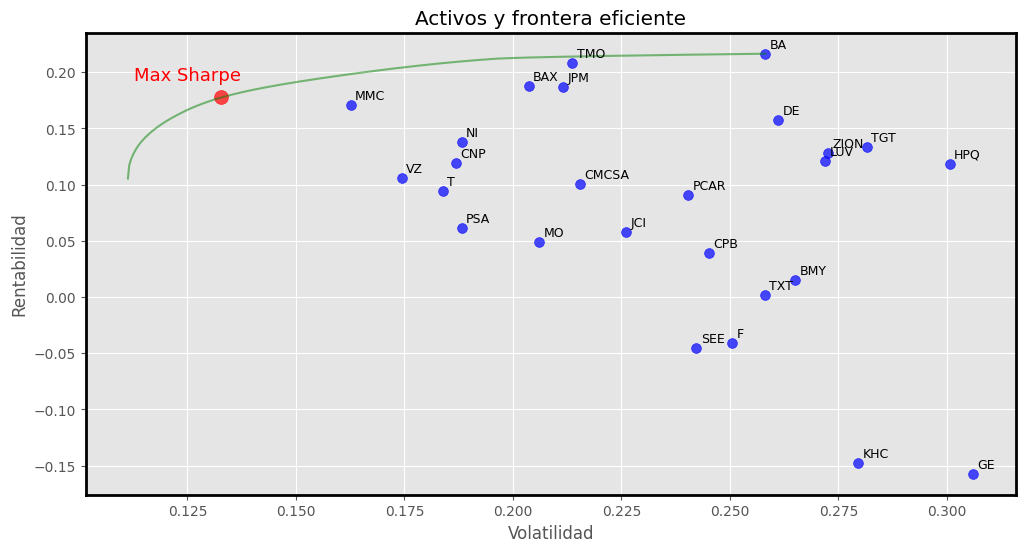

In [ ]:
plt.figure(figsize=(12, 6))

#Offsets for labels
desplazamiento_x = 0.001  # Ajusta este valor según sea necesario
desplazamiento_y = 0.005  # Ajusta este valor según sea necesario



#plt.scatter(cartera_sharpe_max[0], 252 * cartera_sharpe_max[1], c='red', marker='o', s=100, alpha=0.7)
plt.text(std_sharpe - 20* desplazamiento_x, retorno_cart_sharpe+3*desplazamiento_y , 'Max Sharpe', fontsize=13, color='red')
plt.scatter(std_sharpe, retorno_cart_sharpe, c='red', marker='o', s=100, alpha=0.7)

# plt.scatter(np.sqrt(252*min_riesgo[0]), 252*min_riesgo[1], c='red', marker='x', s=50, alpha=0.7)
# plt.text(np.sqrt(252*min_riesgo[0])+ 3*desplazamiento_x, 252*min_riesgo[1] +  2*desplazamiento_y , 'Min riesgo', fontsize=13, color='red')

# Puntos de cada activo
plt.scatter(np.sqrt(np.diag(matriz_cov)*252),252* retornos_esperados, color='blue', s=50, alpha=0.7)
plt.plot(np.sqrt(252)*riesgos_lst, 252*np.array(retornos_lst), '-', color='green', label='Frontera Eficiente', alpha=0.5)


# Añadiendo los nombres de los activos con un desplazamiento


for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]*252) + desplazamiento_x, 252*retornos_esperados[i]+desplazamiento_y , asset, fontsize=9)
plt.xlabel('Volatilidad')
plt.ylabel('Rentabilidad')
plt.title('Activos y frontera eficiente')
#plt.colorbar(label='Sharpe ratio')



# Configurar el borde de la figura
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2)


plt.show()

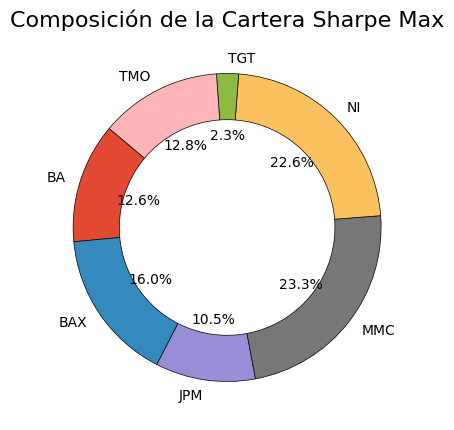

In [ ]:
# Crear el gráfico de donut
plt.figure(figsize=(5, 5))

plt.pie(pesos_filtrados, labels=activos_filtrados, autopct='%1.1f%%', startangle=140, wedgeprops={'width': 0.3, 'edgecolor': 'black'})

# Añadir título
plt.title('Composición de la Cartera Sharpe Max', fontsize=16)

# Mostrar el gráfico
plt.show()

### EXERCISE

Your financial advisor has suggested that the universe of assets in which to invest are those on the assets list we have been using in this notebook, plus the risk-free asset that gives an annual return equal to ret_rf. You have decided that, in order to pay all your expenses, you need to earn a return of 10% per annum. Calculate the portfolio you would form.

In [ ]:
# Decision variable (portfolio weights)
r_esperado = 0.1

In [ ]:
print(f' We know that the profitability and volatility of the maximum Sharpe ratio portfolio are: {retorno_cart_sharpe:.2f} , {std_sharpe:.2f}')

 We know that the profitability and volatility of the maximum Sharpe ratio portfolio are: 0.18 , 0.13


Using the mixed portfolio return formula, we calculate the investment in the risk-free asset:

$$\quad \boxed{w = \frac{r_p - \mu}{r_f - \mu}}$$

In [ ]:
w = (r_esperado- retorno_cart_sharpe)/(ret_rf*252 - retorno_cart_sharpe)
w

np.float64(0.5255027456317376)

In [ ]:
rentabilidad_cartera = w*ret_rf*252 + (1-w)*retorno_cart_sharpe
volatilidad_cartera = np.sqrt((w*0)**2 + (1-w)**2 * std_sharpe**2)

print(f' The profitability and volatility of the portfolio with an expected return of 10% are: {rentabilidad_cartera:.2f} , {volatilidad_cartera:.2f}')

 The profitability and volatility of the portfolio with an expected return of 10% are: 0.10 , 0.06
